# 04 · Trap 2: a novelty effect that fades

Users react to *anything new* on a screen they use out of habit: they look around, tap
the shiny photos, try the new row. That curiosity converts into orders for a while, then
wears off. A test that only measures users' first week measures the curiosity.

Our primary metric is, by construction, each user's first 7 days with the redesign. The
test kept running through day 27 (pre-registered for exactly this reason), so early enrollees
have up to 4 weeks of exposure. The key move: **index time by days since each user's
first exposure, not by calendar day.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pizza_ab.simulate import load_or_simulate
from pizza_ab.metrics import long_run_user, _orders_with_exposure
from pizza_ab.novelty import lift_by_exposure_day, fit_novelty, novelty_model
from pizza_ab.stats import ratio_test
from pizza_ab.config import TEST_DAYS, PLATFORMS
from pizza_ab import plots

plots.set_style()
users, orders = load_or_simulate("experiment")

## 1. Lift by days since first exposure

For each s = 0, 1, 2, … compare the treatment and control order rate among users on their
s-th day of exposure. Both arms are compared on the same calendar days (randomization is
within each enrollment cohort), so weekday effects cancel in the ratio.

In [2]:
lift = lift_by_exposure_day(users, orders)   # see src/pizza_ab/novelty.py
lift.head(8).style.format({"lift": "{:+.1%}", "se_log": "{:.3f}", "lo": "{:+.1%}", "hi": "{:+.1%}"})

,lift,se_log,lo,hi
s,,,,
0,+18.8%,0.041,+9.6%,+28.7%
1,+10.9%,0.041,+2.4%,+20.1%
2,+12.6%,0.041,+4.0%,+21.9%
3,+0.8%,0.041,-7.0%,+9.3%
4,+11.2%,0.041,+2.5%,+20.6%
5,+3.9%,0.042,-4.3%,+12.9%
6,+0.2%,0.041,-7.6%,+8.7%
7,+2.0%,0.042,-5.9%,+10.7%


Fit a decay model on the log rate ratio, weighting each day by its precision:

$$\log\frac{r_T(s)}{r_C(s)} = \log(1 + L) + \log\left(1 + N e^{-s/\tau}\right)$$

**L** is the effect after the curiosity is gone, **N** the initial novelty boost, **τ** its
decay time in days.

**Uncertainty: bootstrap by user, not by day.** The 28 daily points are not independent: the
same users appear at every s they are observed. `curve_fit`'s standard errors assume
independence, so we resample *users* (Poisson bootstrap, 200 draws), refit each time, and take
percentile intervals. The naive intervals are shown next to them for comparison.

In [3]:
fit = fit_novelty(users, orders, n_boot=200)
params = fit["estimate"].to_numpy()
s = lift.index.to_numpy()
fit.rename(index={"L": "L: lift after novelty", "N": "N: initial novelty boost", "tau": "τ: decay (days)"},
           columns={"ci_low": "bootstrap 2.5%", "ci_high": "bootstrap 97.5%",
                    "naive_ci_low": "naive 2.5%", "naive_ci_high": "naive 97.5%"}).style.format("{:.3f}")

,estimate,bootstrap 2.5%,bootstrap 97.5%,naive 2.5%,naive 97.5%
L: lift after novelty,0.022,-0.008,0.040,-0.002,0.045
N: initial novelty boost,0.161,0.085,0.250,0.075,0.247
τ: decay (days),2.178,0.895,5.050,0.024,4.332


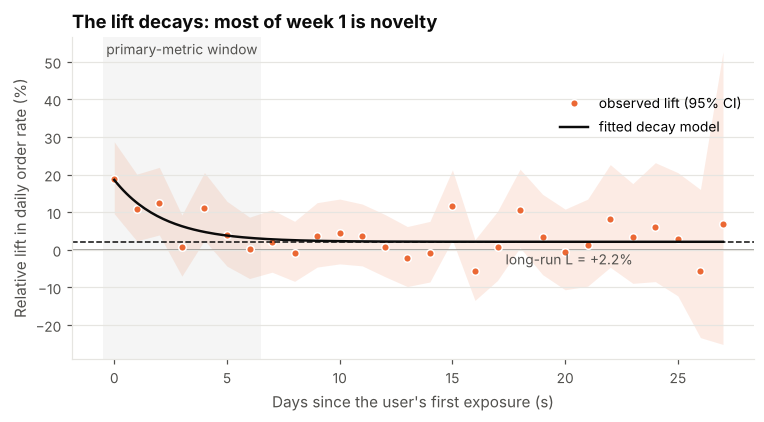

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(s, lift["lo"] * 100, lift["hi"] * 100, color=plots.TREATMENT, alpha=0.13, lw=0)
ax.plot(s, lift["lift"] * 100, "o", color=plots.TREATMENT, ms=5, mec="white", label="observed lift (95% CI)")
ss = np.linspace(0, s.max(), 200)
ax.plot(ss, np.expm1(novelty_model(ss, *params)) * 100, color=plots.TEXT, lw=1.6, label="fitted decay model")
ax.axhline(params[0] * 100, color=plots.TEXT, lw=1, ls="--")
ax.text(s.max() - 4, params[0] * 100 - 6, f"long-run L = {params[0]:+.1%}", ha="right", fontsize=9, color=plots.TEXT_2)
ax.axvspan(-0.5, 6.5, color=plots.MUTED, alpha=0.08, lw=0)
ax.text(3, ax.get_ylim()[1] * 0.92, "primary-metric window", ha="center", fontsize=9, color=plots.TEXT_2)
plots.zero_line(ax)
ax.set_xlabel("Days since the user's first exposure (s)")
ax.set_ylabel("Relative lift in daily order rate (%)")
ax.set_title("The lift decays: most of week 1 is novelty")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.86))
plots.save(fig, "04_novelty_decay");

## 2. Week-by-week, as a ratio metric with the delta method

The per-day curve is noisy at large s (only early enrollees get there). Bucketing by
exposure week and computing **orders per user-day** gives tighter estimates. This is a
ratio of two per-user sums, so its variance must account for the fact that one user
contributes many days: we use the delta method, clustered at the user level.

In [5]:
o = _orders_with_exposure(users, orders)

def week_table(u, weeks=((0, 6), (7, 13), (14, 20), (21, 27))):
    rows = []
    for a, b in weeks:
        days = np.clip(np.minimum(b, TEST_DAYS - 1 - u["enroll_day"]) - a + 1, 0, None)
        sub = u.assign(days=days)
        sub = sub[sub["days"] > 0]
        cnt = o[(o["s"] >= a) & (o["s"] <= b)].groupby("user_id").size()
        sub = sub.assign(n=sub["user_id"].map(cnt).fillna(0))
        c, t = sub[sub.variant == "control"], sub[sub.variant == "treatment"]
        r = ratio_test(c["n"], c["days"], t["n"], t["days"])
        rows.append({"exposure week": f"week {a//7 + 1} (s={a}-{b})", "users": len(sub),
                     "lift": r.rel_lift, "ci_low": r.rel_ci[0], "ci_high": r.rel_ci[1], "p": r.p_value})
    return pd.DataFrame(rows).set_index("exposure week")

fmt = {"users": "{:,}", "lift": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}", "p": "{:.3f}"}
weeks_all = week_table(users)
weeks_all.style.format(fmt)

,users,lift,ci_low,ci_high,p
exposure week,,,,,
week 1 (s=0-6),"125,528",+8.2%,+4.8%,+11.7%,0.000
week 2 (s=7-13),"125,528",+1.7%,-1.6%,+4.9%,0.309
week 3 (s=14-20),"125,528",+2.6%,-1.1%,+6.2%,0.160
week 4 (s=21-27),"62,723",+3.5%,-2.4%,+9.5%,0.233


**A composition check.** Later weeks only contain early enrollees (a day-13 enrollee never
reaches week 3). In real products, early enrollees skew toward heavy users, so a
shrinking lift could reflect *who* is measured rather than *when*. Re-run on a fixed cohort —
users enrolled on days 0–6, all of whom are observed through week 3 — so the same people
appear in every row.

In [6]:
fixed = users[users["enroll_day"] <= 6]
weeks_fixed = week_table(fixed, weeks=((0, 6), (7, 13), (14, 20)))
weeks_fixed.style.format(fmt)

,users,lift,ci_low,ci_high,p
exposure week,,,,,
week 1 (s=0-6),"62,723",+7.5%,+2.6%,+12.3%,0.002
week 2 (s=7-13),"62,723",+3.3%,-1.4%,+7.9%,0.164
week 3 (s=14-20),"62,723",+2.5%,-2.1%,+7.1%,0.290


The point estimates fall the same way within a fixed set of users (+7.5% → +3.3% → +2.5%), which
is what a time effect predicts. Two honest caveats: the week-by-week CIs overlap a lot at this
cohort size, so this is consistency, not proof; and in this simulator enrollment day is
independent of ordering frequency by construction, so the check *cannot* fail here. On real
data it can, and that is when it matters.

**Why the delta method matters.** Treating each user-day as an independent observation
(a naive Poisson test) ignores that heavy users contribute many correlated days, which
understates the standard error:

In [7]:
lr = long_run_user(users, orders)              # days s >= 7 only
c, t = lr[lr.variant == "control"], lr[lr.variant == "treatment"]
r = ratio_test(c["lr_orders"], c["lr_days"], t["lr_orders"], t["lr_days"])
se_delta = (r.rel_ci[1] - r.rel_ci[0]) / (2 * 1.96)
se_naive = np.sqrt(1 / c["lr_orders"].sum() + 1 / t["lr_orders"].sum()) * (1 + r.rel_lift)
print(f"Long-run lift (days 7+): {r.rel_lift:+.2%}")
print(f"SE, naive per-user-day Poisson: {se_naive:.4f}")
print(f"SE, delta method (user-clustered): {se_delta:.4f}  → {se_delta/se_naive:.2f}× wider")

Long-run lift (days 7+): +2.26%
SE, naive per-user-day Poisson: 0.0111
SE, delta method (user-clustered): 0.0121  → 1.09× wider


Only ~9% wider here, because pizza orders are sparse and few users order more than once.
For dense per-user metrics (sessions, clicks, page views) the naive SE can be badly
too small; the delta method is the default for any ratio metric.

## 3. Does the novelty look the same on both platforms?

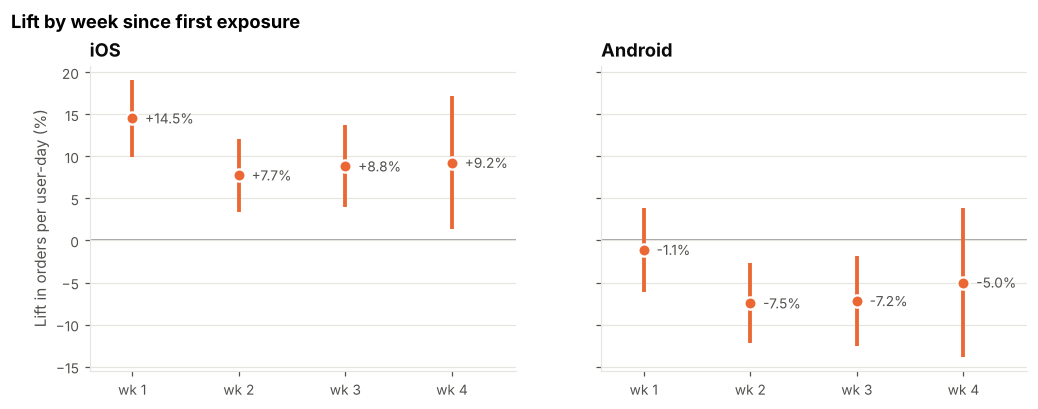

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
plat_weeks = {}
for ax, plat in zip(axes, PLATFORMS):
    wt = week_table(users[users["platform"] == plat])
    plat_weeks[plat] = wt
    x = np.arange(len(wt))
    ax.vlines(x, wt["ci_low"] * 100, wt["ci_high"] * 100, color=plots.TREATMENT, lw=2.5)
    ax.plot(x, wt["lift"] * 100, "o", color=plots.TREATMENT, ms=8, mec="white", mew=1.5)
    for xi, v in zip(x, wt["lift"]):
        ax.text(xi + 0.12, v * 100, f"{v:+.1%}", va="center", fontsize=9, color=plots.TEXT_2)
    plots.zero_line(ax)
    ax.set_xticks(x, [f"wk {i+1}" for i in x])
    ax.set_xlim(-0.4, len(wt) - 0.4)
    ax.set_title(plat)
axes[0].set_ylabel("Lift in orders per user-day (%)")
fig.suptitle("Lift by week since first exposure", x=0.06, ha="left", fontweight="bold", fontsize=12, y=1.02)
plots.save(fig, "04_novelty_by_platform");

pd.concat(plat_weeks, names=["platform"]).style.format(fmt)

The novelty boost is similar on both platforms; what it decays **to** is not. On iOS the
effect settles at a solid positive level. On Android, week-1 curiosity masks a real
loss in weeks 2–4. That is notebook 05.

## 4. Takeaways

* The primary metric (+7.6%) is mostly novelty. On the same metric (orders per user-day), the
  lift is **+8.2% in week 1 and +2.3% over days 7–27**, with a 95% CI that includes zero.
* "Days 7–27" is weeks 2–4, not forever: late enrollees contribute only days 7–14, and under the
  fitted decay a little novelty is still left at day 7. Calling it "long run" is shorthand.
* The decay model puts the initial boost at roughly +16% decaying over ~2 days — but read
  those two numbers loosely: their user-level bootstrap intervals are wide (N: about +9% to +25%;
  τ: about 1 to 5 days). What is
  robust is the shape: a large first-days boost that is gone by week 2, so a 7-day window
  cannot escape it. Novelty-prone changes need a primary metric measured after
  a burn-in, or a test long enough to read weeks 3–4.
* **Novelty vs. learning.** The opposite pattern — an effect that starts negative and
  *improves* — is change aversion (a primacy effect): users need time to learn a new layout.
  Same diagnosis, opposite conclusion; never judge a UI change on week 1 alone.
* Other ways to confirm novelty in practice: compare *new* users (who have no habit to break)
  with existing users, or keep a long-term holdout after launch.